# 03 — HED stain augmentation at 64×64, three seeds

**Question:** does training with random stain changes make the models less sensitive to staining differences, without hurting clean accuracy?

**Background:** in notebook 02, every model scored ~0.995 val macro-F1 on clean validation images, but lost 3–9 points under a simulated 30% stain shift (`results/hed_shift_val.csv`). Clean validation cannot tell the models apart; the stain-shifted versions can.

**Design:** 3 models × {no augmentation, HED augmentation σ = 0.2} × seeds {0, 1, 2} = 18 runs. The 3 seed-0 runs without augmentation already exist from notebook 02 and are reused, so 15 new runs. Everything else matches notebook 02 (same learning rates, schedule, early stopping).

**Augmentation:** each training image gets its hematoxylin and eosin amounts scaled by independent random factors in [0.8, 1.2], on the GPU, every batch. Validation images are never augmented. The upsampled 64→224 model is left out here because each run takes about 50 minutes.

**Caveat:** the augmentation uses the same kind of change as the shifted validation sets, so augmented models are partly "practiced" on them. Training uses σ = 0.2 while the strongest evaluation uses σ = 0.30, so that shift is still larger than anything seen in training. The real check is the test set from the other center, at the very end.

**Time:** about 5 min per baseline run and about 8 min per ResNet run, so roughly 2 hours for all 15. The run cell skips finished runs, so it can be re-run after an interruption.

In [1]:
%load_ext autoreload
%autoreload 2

import os
os.environ["TORCH_HOME"] = "/home/ec2-user/SageMaker/.cache/torch"

import json
import numpy as np
import torch
from src.data import load_split, DATA_ROOT, GPUPreprocess, hed_jitter
from src.engine import run_experiment
from src.hed_shift import make_val_versions, show_grid, evaluate_runs, summarize_seeds

device = torch.device("cuda")
print("PyTorch", torch.__version__, "| GPU:", torch.cuda.get_device_name(0))

PyTorch 2.10.0+cu128 | GPU: Tesla T4


## 1. Sanity checks before training

**(a) GPU version matches the scikit-image version.** With fixed factors (20% more H, 20% less E), the GPU augmentation should give the same images as `hed_perturb` up to rounding. The difference should be tiny (around 1e-5 or smaller).

In [2]:
from skimage.color import rgb2hed, hed2rgb

x, _ = load_split(DATA_ROOT, 64, "val")
x = np.asarray(x[:256])
xt = torch.from_numpy(x).permute(0, 3, 1, 2).float().to(device) / 255
prep = GPUPreprocess(device, hed_sigma=0.2)

alpha = torch.tensor([1.2, 0.8, 1.0], device=device).view(1, 3, 1, 1)
gpu = hed_jitter(xt, 0.2, prep.hed_from_rgb, prep.rgb_from_hed, alpha=alpha)
gpu = gpu.permute(0, 2, 3, 1).cpu().numpy()

ref = rgb2hed(x)
ref[..., 0] *= 1.2
ref[..., 1] *= 0.8
ref = np.clip(hed2rgb(ref), 0, 1)
print("max abs difference vs scikit-image:", np.abs(gpu - ref).max())

max abs difference vs scikit-image: 2.202462526801341e-07


**(b) What training images look like.** Row 1 is the original; rows 2 and 3 are two random augmentations of the same images (σ = 0.2). They should look like believable slides with slightly different staining.

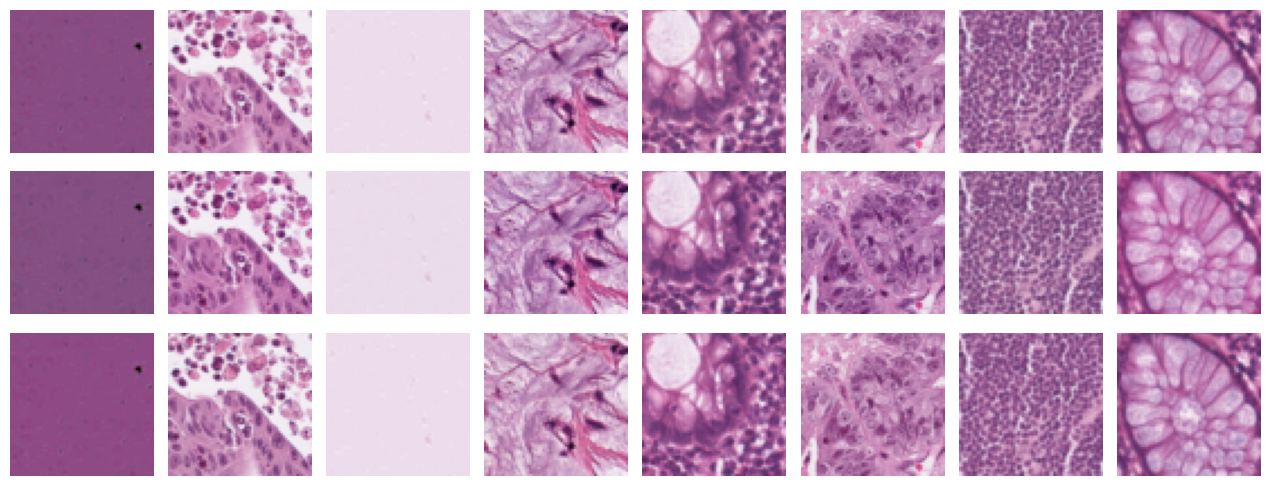

In [3]:
def to_uint8(t):
    return (t.permute(0, 2, 3, 1).cpu().numpy() * 255).round().astype(np.uint8)

augs = [to_uint8(hed_jitter(xt, 0.2, prep.hed_from_rgb, prep.rgb_from_hed)) for _ in range(2)]
show_grid(x, *augs);

**(c) Smoke test.** A few batches with augmentation on, nothing saved.

In [4]:
_ = run_experiment("smoke_test", "baseline_cnn", hed_sigma=0.2, epochs=1, limit_batches=20, save=False)

=== smoke_test: baseline_cnn, data 64x64, network input 64x64, HED aug 0.2, seed 0, 0.39M params, device cuda ===
ep 01 | lr 1.0e-03 | train loss 1.230 acc 0.552 F1 0.529 | val loss 1.952 acc 0.237 F1 0.110 | 5s  *best
Best epoch 1: val acc 0.2375, val macro-F1 0.1096, 4s/epoch train, 29625 img/s inference. Saved: (not saved)



## 2. Training runs

Order: the augmented seed-0 runs first (they pair with the existing seed-0 runs from notebook 02, so a first comparison is ready after ~20 minutes), then seeds 1 and 2.

In [8]:
TRAIN_HED = 0.2
LRS = {"baseline_cnn": 1e-3, "resnet18_scratch": 1e-3, "resnet18_pretrained": 1e-4}
COMMON = dict(data_size=64, epochs=30, batch_size=128)
SEEDS = [0, 1, 2]

def run_name(model, seed, hed):
    if seed == 0 and hed == 0:
        return f"{model}_64"  # existing runs from notebook 02
    aug = f"_hed{round(hed * 100)}" if hed else ""
    return f"{model}_64{aug}_s{seed}"

def is_done(name):
    path = f"results/{name}.json"
    if not os.path.exists(path):
        return False
    with open(path) as f:
        return json.load(f).get("status") == "done"

PLAN = [(0, TRAIN_HED), (1, 0.0), (1, TRAIN_HED), (2, 0.0), (2, TRAIN_HED)]
for seed, hed in PLAN:
    for model, lr in LRS.items():
        name = run_name(model, seed, hed)
        if is_done(name):
            print(f"skip (already done): {name}")
            continue
        run_experiment(name, model, lr=lr, seed=seed, hed_sigma=hed, **COMMON)

skip (already done): baseline_cnn_64_hed20_s0
skip (already done): resnet18_scratch_64_hed20_s0
skip (already done): resnet18_pretrained_64_hed20_s0
skip (already done): baseline_cnn_64_s1
skip (already done): resnet18_scratch_64_s1
skip (already done): resnet18_pretrained_64_s1
skip (already done): baseline_cnn_64_hed20_s1
skip (already done): resnet18_scratch_64_hed20_s1
skip (already done): resnet18_pretrained_64_hed20_s1
skip (already done): baseline_cnn_64_s2
skip (already done): resnet18_scratch_64_s2
skip (already done): resnet18_pretrained_64_s2
skip (already done): baseline_cnn_64_hed20_s2
skip (already done): resnet18_scratch_64_hed20_s2
skip (already done): resnet18_pretrained_64_hed20_s2


## 3. Evaluate on clean and stain-shifted validation

Same three validation versions as notebook 02: clean, 15% shift, 30% shift. This cell only uses finished runs, so it also works partway through.

In [9]:
versions, labels = make_val_versions()  # clean, hed_0.15, hed_0.30
names = [run_name(m, s, h) for s in SEEDS for h in (0.0, TRAIN_HED) for m in LRS]
names = [n for n in names if is_done(n)]
table = evaluate_runs(names, versions, labels)
table.to_csv("results/hed_aug_64_eval.csv")
table

done: baseline_cnn_64
done: resnet18_scratch_64
done: resnet18_pretrained_64
done: baseline_cnn_64_hed20_s0
done: resnet18_scratch_64_hed20_s0
done: resnet18_pretrained_64_hed20_s0
done: baseline_cnn_64_s1
done: resnet18_scratch_64_s1
done: resnet18_pretrained_64_s1
done: baseline_cnn_64_hed20_s1
done: resnet18_scratch_64_hed20_s1
done: resnet18_pretrained_64_hed20_s1
done: baseline_cnn_64_s2
done: resnet18_scratch_64_s2
done: resnet18_pretrained_64_s2
done: baseline_cnn_64_hed20_s2
done: resnet18_scratch_64_hed20_s2
done: resnet18_pretrained_64_hed20_s2


,model,input,train HED,seed,best epoch,clean F1,hed_0.15 F1,hed_0.30 F1,hed_0.15 drop,hed_0.30 drop
run,,,,,,,,,,
baseline_cnn_64,baseline_cnn,64,0.0,0,28,0.9953,0.9860,0.9381,0.0093,0.0572
resnet18_scratch_64,resnet18_scratch,64,0.0,0,27,0.9945,0.9791,0.9094,0.0154,0.0851
resnet18_pretrained_64,resnet18_pretrained,64,0.0,0,28,0.9953,0.9887,0.9561,0.0066,0.0392
baseline_cnn_64_hed20_s0,baseline_cnn,64,0.2,0,26,0.9930,0.9918,0.9905,0.0012,0.0025
resnet18_scratch_64_hed20_s0,resnet18_scratch,64,0.2,0,23,0.9919,0.9915,0.9891,0.0004,0.0028
resnet18_pretrained_64_hed20_s0,resnet18_pretrained,64,0.2,0,22,0.9936,0.9930,0.9907,0.0006,0.0029
baseline_cnn_64_s1,baseline_cnn,64,0.0,1,30,0.9957,0.9855,0.9367,0.0102,0.0590
resnet18_scratch_64_s1,resnet18_scratch,64,0.0,1,22,0.9941,0.9807,0.9038,0.0134,0.0903
resnet18_pretrained_64_s1,resnet18_pretrained,64,0.0,1,24,0.9951,0.9883,0.9619,0.0068,0.0332


### Summary over seeds (mean ± standard deviation)

In [10]:
summary = summarize_seeds(table)
summary.to_csv("results/hed_aug_64_summary.csv")
summary

seeds         clean F1      hed_0.15 F1  \
model               input train HED                                            
baseline_cnn        64    0.0            3  0.9955 ± 0.0002  0.9855 ± 0.0005   
                          0.2            3  0.9931 ± 0.0011  0.9924 ± 0.0012   
resnet18_pretrained 64    0.0            3  0.9954 ± 0.0004  0.9884 ± 0.0003   
                          0.2            3  0.9938 ± 0.0008  0.9930 ± 0.0004   
resnet18_scratch    64    0.0            3  0.9943 ± 0.0002  0.9799 ± 0.0008   
                          0.2            3  0.9914 ± 0.0005  0.9908 ± 0.0007   

                                         hed_0.30 F1    hed_0.15 drop  \
model               input train HED                                     
baseline_cnn        64    0.0        0.9378 ± 0.0010  0.0100 ± 0.0006   
                          0.2        0.9907 ± 0.0020  0.0007 ± 0.0004   
resnet18_pretrained 64    0.0        0.9585 ± 0.0030  0.0070 ± 0.0005   
                          0.2        0.9917 ± 0.0011  0.0008 ± 0.0004   
resnet18_scratch    64    0.0        0.9058 ± 0.0032  0.0144 ± 0.0010   
                          0.2        0.9889 ± 0.0003  0.0006 ± 0.0003   

                                       hed_0.30 drop  
model               input train HED                   
baseline_cnn        64    0.0        0.0577 ± 0.0011  
                          0.2        0.0024 ± 0.0009  
resnet18_pretrained 64    0.0        0.0369 ± 0.0032  
                          0.2        0.0021 ± 0.0007  
resnet18_scratch    64    0.0        0.0885 ± 0.0029  
                          0.2        0.0026 ± 0.0004

### What to look for
- **Clean F1, augmented vs. not:** augmentation should not cost clean accuracy. A small drop would be a real trade-off worth reporting.
- **Drop at 30% shift, augmented vs. not:** the main question. Smaller drop = more robust.
- **Seed spread:** if two settings differ by less than about two standard deviations, treat them as tied.
- **Model order:** does pretrained still beat scratch once both are augmented? Augmentation may close part of the gap.